# Модель прогнозирования кредитного дефолта

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('german_credit_data.csv', index_col=0)

In [3]:
print(df.head())

   Age     Sex  Job Housing Saving accounts Checking account  Credit amount  \
0   67    male    2     own             NaN           little           1169   
1   22  female    2     own          little         moderate           5951   
2   49    male    1     own          little              NaN           2096   
3   45    male    2    free          little           little           7882   
4   53    male    2    free          little           little           4870   

   Duration              Purpose  
0         6             radio/TV  
1        48             radio/TV  
2        12            education  
3        42  furniture/equipment  
4        24                  car  


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
dtypes: int64(4), object(5)
memory usage: 78.1+ KB
None


In [5]:
print(df.isnull().sum())

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64


In [6]:
np.random.seed(42)
df['Risk_Score'] = 0

# Факторы риска

In [7]:
df.loc[df['Credit amount'] > 7000, 'Risk_Score'] += 2
df.loc[df['Duration'] > 36, 'Risk_Score'] += 2
df.loc[df['Job'] == 0, 'Risk_Score'] += 3
df.loc[df['Saving accounts'].isna(), 'Risk_Score'] += 2
df.loc[df['Saving accounts'] == 'little', 'Risk_Score'] += 1
df.loc[df['Checking account'].isna(), 'Risk_Score'] += 2
df.loc[df['Checking account'] == 'little', 'Risk_Score'] += 1
df.loc[df['Age'] < 25, 'Risk_Score'] += 1
df.loc[df['Housing'] == 'rent', 'Risk_Score'] += 1

# Создаем целевую переменную с некоторой случайностью

In [8]:
df['Default'] = 0
df.loc[df['Risk_Score'] >= 5, 'Default'] = 1

# Добавляем случайность

In [9]:
random_defaults = np.random.choice([0, 1], size=len(df), p=[0.85, 0.15])
df.loc[df['Risk_Score'] >= 3, 'Default'] = np.random.choice([0, 1], size=sum(df['Risk_Score'] >= 3), p=[0.7, 0.3])

In [10]:
print(f"\nРаспределение целевой переменной:")
print(df['Default'].value_counts())
print(f"Процент дефолтов: {df['Default'].mean()*100:.2f}%")


Распределение целевой переменной:
Default
0    832
1    168
Name: count, dtype: int64
Процент дефолтов: 16.80%


# ПОДГОТОВКА ДАННЫХ 

In [11]:
df['Saving accounts'].fillna('none', inplace=True)
df['Checking account'].fillna('none', inplace=True)

# Кодирование категориальных признаков

In [12]:
le_dict = {}
categorical_columns = ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

for col in categorical_columns:
    le = LabelEncoder()
    df[f'{col}_encoded'] = le.fit_transform(df[col])
    le_dict[col] = le

# Признаки для модели

In [13]:
feature_columns = ['Age', 'Sex_encoded', 'Job', 'Housing_encoded', 
                   'Saving accounts_encoded', 'Checking account_encoded',
                   'Credit amount', 'Duration', 'Purpose_encoded']

X = df[feature_columns]
y = df['Default']

# Разделение на обучающую и тестовую выборки

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [15]:
from sklearn.utils import resample

rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    max_depth=10,
    class_weight='balanced' 
)

# Масштабирование признаков

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nРазмер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")


Размер обучающей выборки: (700, 9)
Размер тестовой выборки: (300, 9)


#  МОДЕЛЬ 1: ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ 

In [17]:
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


# Предсказания

In [18]:
y_pred_lr = log_reg.predict(X_test_scaled)
y_pred_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

# Метрики

In [19]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba_lr):.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.99      0.91       250
           1       0.33      0.02      0.04        50

    accuracy                           0.83       300
   macro avg       0.58      0.51      0.47       300
weighted avg       0.75      0.83      0.76       300

ROC AUC Score: 0.6739


# МОДЕЛЬ 2: RANDOM FOREST

In [20]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


# Предсказания

In [21]:
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

In [22]:
from sklearn.metrics import classification_report, roc_auc_score


print("ИТОГОВАЯ ОЦЕНКА МОДЕЛИ")



print("\nRandom Forest:")
print(f"Accuracy: {rf_model.score(X_test, y_test):.2%}")
print(f"ROC AUC: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


print("\nTop 5 важных признаков:")
feature_imp = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False).head()
print(feature_imp)

ИТОГОВАЯ ОЦЕНКА МОДЕЛИ

Random Forest:
Accuracy: 83.67%
ROC AUC: 0.7432

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       250
           1       0.53      0.16      0.25        50

    accuracy                           0.84       300
   macro avg       0.69      0.57      0.58       300
weighted avg       0.80      0.84      0.80       300


Top 5 важных признаков:
                    feature  importance
6             Credit amount    0.239254
0                       Age    0.178439
7                  Duration    0.148361
5  Checking account_encoded    0.128375
8           Purpose_encoded    0.086100


# Метрики

In [23]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba_rf):.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       250
           1       0.53      0.16      0.25        50

    accuracy                           0.84       300
   macro avg       0.69      0.57      0.58       300
weighted avg       0.80      0.84      0.80       300

ROC AUC Score: 0.7432


# ВИЗУАЛИЗАЦИЯ

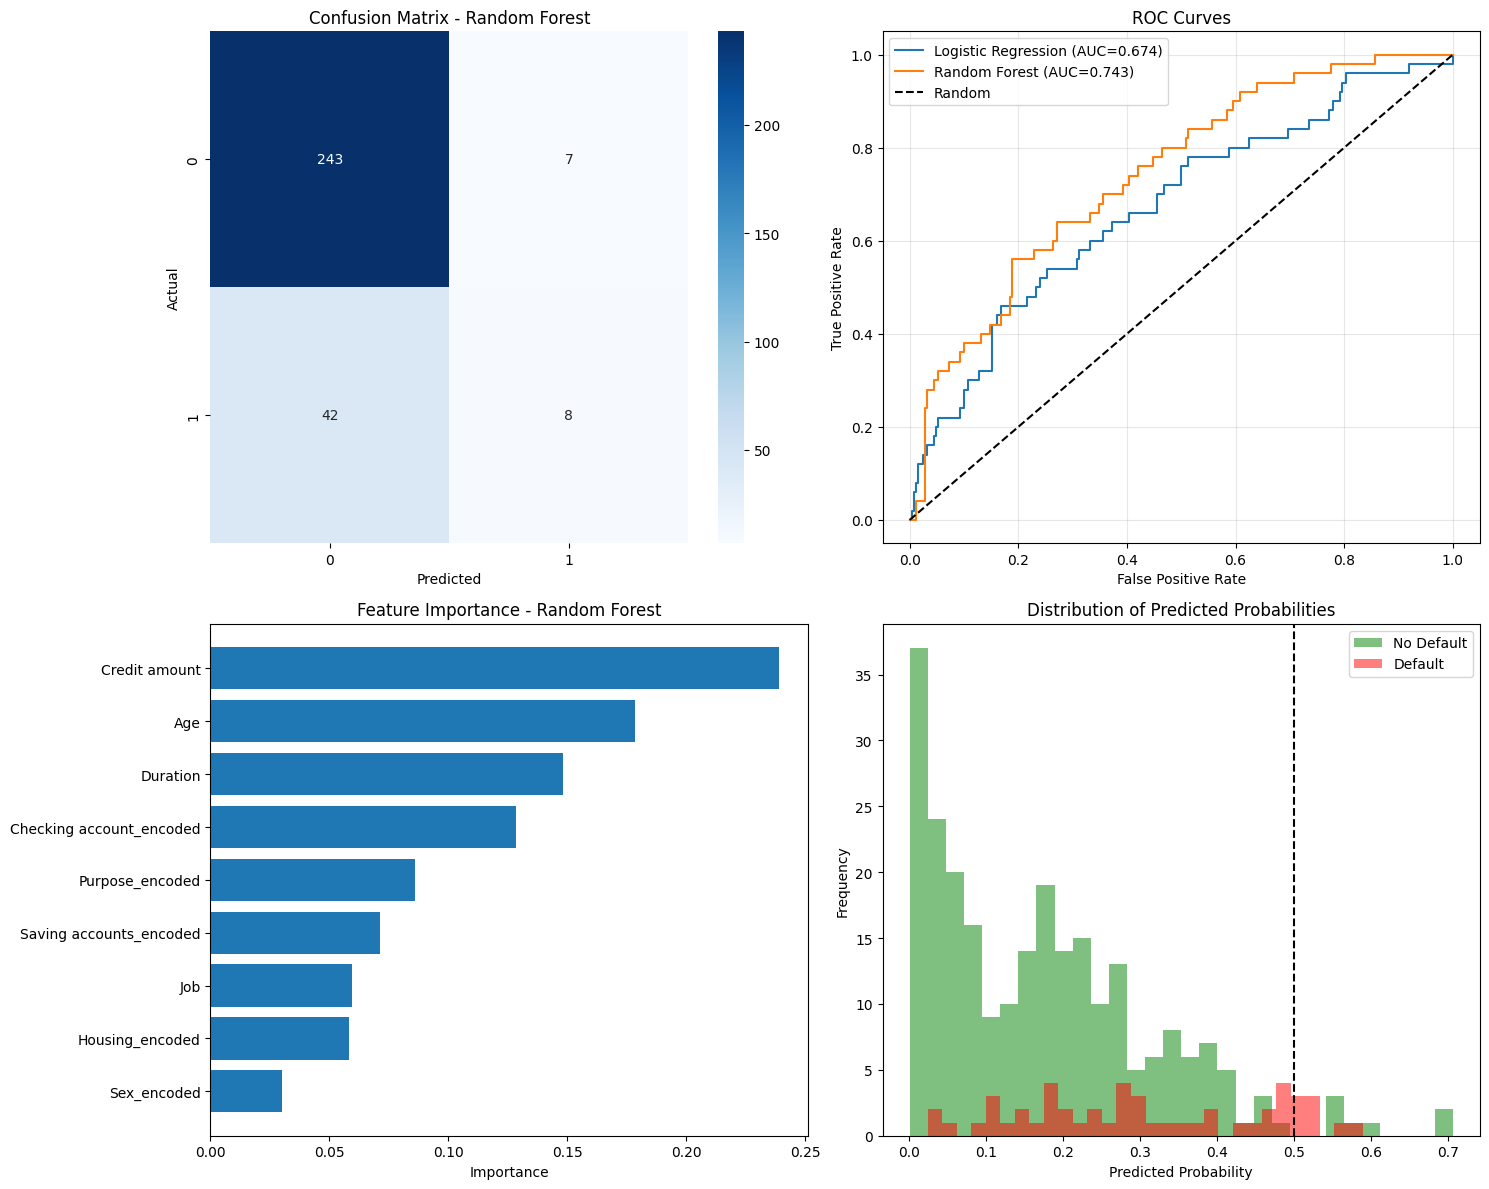

In [24]:

fig, axes = plt.subplots(2, 2, figsize=(15, 12))


cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0])
axes[0, 0].set_title('Confusion Matrix - Random Forest')
axes[0, 0].set_ylabel('Actual')
axes[0, 0].set_xlabel('Predicted')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)

axes[0, 1].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC={roc_auc_score(y_test, y_pred_proba_lr):.3f})')
axes[0, 1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC={roc_auc_score(y_test, y_pred_proba_rf):.3f})')
axes[0, 1].plot([0, 1], [0, 1], 'k--', label='Random')
axes[0, 1].set_xlabel('False Positive Rate')
axes[0, 1].set_ylabel('True Positive Rate')
axes[0, 1].set_title('ROC Curves')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)


feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

axes[1, 0].barh(feature_importance['feature'], feature_importance['importance'])
axes[1, 0].set_xlabel('Importance')
axes[1, 0].set_title('Feature Importance - Random Forest')
axes[1, 0].invert_yaxis()


axes[1, 1].hist(y_pred_proba_rf[y_test == 0], bins=30, alpha=0.5, label='No Default', color='green')
axes[1, 1].hist(y_pred_proba_rf[y_test == 1], bins=30, alpha=0.5, label='Default', color='red')
axes[1, 1].set_xlabel('Predicted Probability')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].set_title('Distribution of Predicted Probabilities')
axes[1, 1].legend()
axes[1, 1].axvline(x=0.5, color='black', linestyle='--', label='Threshold')

plt.tight_layout()
plt.show()

#  ФУНКЦИЯ ДЛЯ ПРЕДСКАЗАНИЯ

In [25]:
def predict_default(age, sex, job, housing, saving_acc, checking_acc, credit_amount, duration, purpose):
    """
    Предсказание вероятности дефолта для нового клиента
    """
    try:
        new_data = pd.DataFrame({
            'Age': [age],
            'Sex': [sex],
            'Job': [job],
            'Housing': [housing],
            'Saving accounts': [saving_acc],
            'Checking account': [checking_acc],
            'Credit amount': [credit_amount],
            'Duration': [duration],
            'Purpose': [purpose]
        })
        
        for col in categorical_columns:
            new_data[f'{col}_encoded'] = le_dict[col].transform(new_data[col])
        

        X_new = new_data[feature_columns]
        
   
        probability = rf_model.predict_proba(X_new)[0, 1]
        prediction = rf_model.predict(X_new)[0]
        
        print(f"\n{'-'*60}")
        print(f"ПРЕДСКАЗАНИЕ ДЛЯ НОВОГО КЛИЕНТА")
        print(f"{'-'*60}")
        print(f"Возраст: {age}")
        print(f"Пол: {sex}")
        print(f"Работа: {job}")
        print(f"Жилье: {housing}")
        print(f"Сбережения: {saving_acc}")
        print(f"Текущий счет: {checking_acc}")
        print(f"Сумма кредита: {credit_amount}")
        print(f"Срок (мес): {duration}")
        print(f"Цель: {purpose}")
        print(f"\n{'-'*60}")
        print(f"Вероятность дефолта: {probability*100:.2f}%")
        

        if probability < 0.3:
            decision = "ОДОБРИТЬ (низкий риск)"
        elif probability < 0.5:
            decision = "РАССМОТРЕТЬ (средний риск)"
        else:
            decision = "ОТКАЗАТЬ (высокий риск)"
            
        print(f"Решение: {decision}")
        print(f"{'-'*60}\n")
        
        return probability, prediction
        
    except Exception as e:
        print(f"Ошибка при предсказании: {e}")
        return None, None

# Примеры предсказаний

# Пример 1: Низкий риск

In [26]:

predict_default(
    age=35,
    sex='male',
    job=2,
    housing='own',
    saving_acc='rich',
    checking_acc='moderate',
    credit_amount=3000,
    duration=12,
    purpose='car'
)




------------------------------------------------------------
ПРЕДСКАЗАНИЕ ДЛЯ НОВОГО КЛИЕНТА
------------------------------------------------------------
Возраст: 35
Пол: male
Работа: 2
Жилье: own
Сбережения: rich
Текущий счет: moderate
Сумма кредита: 3000
Срок (мес): 12
Цель: car

------------------------------------------------------------
Вероятность дефолта: 0.04%
Решение: ОДОБРИТЬ (низкий риск)
------------------------------------------------------------



(np.float64(0.00037208590131301915), np.int64(0))

# Пример 2: Высокий риск

In [27]:


predict_default(
    age=22,
    sex='female',
    job=0,
    housing='rent',
    saving_acc='little',
    checking_acc='little',
    credit_amount=15000,
    duration=60,
    purpose='business'
)



------------------------------------------------------------
ПРЕДСКАЗАНИЕ ДЛЯ НОВОГО КЛИЕНТА
------------------------------------------------------------
Возраст: 22
Пол: female
Работа: 0
Жилье: rent
Сбережения: little
Текущий счет: little
Сумма кредита: 15000
Срок (мес): 60
Цель: business

------------------------------------------------------------
Вероятность дефолта: 43.00%
Решение: РАССМОТРЕТЬ (средний риск)
------------------------------------------------------------



(np.float64(0.43), np.int64(0))

# Пример 3: Средний риск

In [28]:

predict_default(
    age=40,
    sex='male',
    job=2,
    housing='own',
    saving_acc='moderate',
    checking_acc='none',
    credit_amount=7000,
    duration=36,
    purpose='education'
)



------------------------------------------------------------
ПРЕДСКАЗАНИЕ ДЛЯ НОВОГО КЛИЕНТА
------------------------------------------------------------
Возраст: 40
Пол: male
Работа: 2
Жилье: own
Сбережения: moderate
Текущий счет: none
Сумма кредита: 7000
Срок (мес): 36
Цель: education

------------------------------------------------------------
Вероятность дефолта: 39.52%
Решение: РАССМОТРЕТЬ (средний риск)
------------------------------------------------------------



(np.float64(0.3952301842174706), np.int64(0))

# МОДЕЛЬ ГОТОВА К ИСПОЛЬЗОВАНИЮ!